# Maximum-Sharpe allocation

Original project: Spark Hu, November 2025. Technical corrections prepared with Codex assistance on 5 October 2026. Documentation revised on 18 October 2026.

This is an **in-sample allocation illustration** using MSFT, JPM, TLT, GLD and BTC-USD. We estimate mean and covariance on the full historical sample, then choose long-only weights. It is not a test of how those fitted weights would have performed on unseen future returns.

The original project files remain at the repository root. The local price snapshot was freshly retrieved for this revision; it is not the unarchived original download.

## 1. Price alignment

The combined download has weekend rows because it contains BTC. The analysis first retains dates with complete prices for this asset universe. Explicit ticker ordering and labelled weights prevent confusing one asset's allocation with another's. `load_snapshot` verifies the input file's recorded hash and makes no network request.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display, Image
from allocation import (prepare_prices, simple_returns, max_sharpe_weights,
                        fixed_weight_returns, performance_metrics, daily_risk_free)
from fetch_data import load_snapshot
from run_analysis import MVO_TICKERS, RESULTS, SEED, portfolio_cloud
RESULTS.mkdir(exist_ok=True)
raw = load_snapshot()
prices = prepare_prices(raw, MVO_TICKERS, start='2021-01-01', end='2025-01-01')
print('Price dates:', prices.index[0].date(), 'to', prices.index[-1].date())
print('Common price observations:', len(prices))
display(prices.head())

Price dates: 2021-01-04 to 2024-12-31
Common price observations: 1005


,MSFT,JPM,TLT,GLD,BTC-USD
Date,,,,,
2021-01-04,207.565399,109.000519,130.172989,182.330002,31971.914062
2021-01-05,207.765594,109.593636,129.206284,182.869995,33992.429688
2021-01-06,202.378387,114.739685,126.553917,179.899994,36824.363281
2021-01-07,208.137466,118.507637,125.438408,179.479996,39371.042969
2021-01-08,209.405579,118.638496,125.033524,173.339996,40797.609375


## 2. Simple-return mean and covariance

An asset's simple return is $r_{j,t}=P_{j,t}/P_{j,t-1}-1$. For beginning-of-interval weights, $r_{p,t}=\sum_jw_jr_{j,t}$ is exact. The fitted portfolio mean is $w^T\hat\mu$ and its variance is $w^TSw$. The sample covariance below uses the usual $n-1$ denominator.

These quantities estimate the historical sample. Their accuracy for another period is a separate statistical question.

In [2]:
returns = simple_returns(prices)
display(pd.DataFrame({'daily_mean': returns.mean(), 'daily_std': returns.std()}))
display(returns.cov())
print('Return observations:', len(returns))

,daily_mean,daily_std
MSFT,0.000827,0.016426
JPM,0.000865,0.015206
TLT,-0.000418,0.010671
GLD,0.000323,0.009025
BTC-USD,0.001845,0.039408


,MSFT,JPM,TLT,GLD,BTC-USD
MSFT,0.000270,6.815777e-05,0.000012,1.688188e-05,0.000195
JPM,0.000068,2.312263e-04,-0.000024,4.218781e-07,0.000144
TLT,0.000012,-2.446007e-05,0.000114,2.910300e-05,-0.000002
GLD,0.000017,4.218781e-07,0.000029,8.145280e-05,0.000024
BTC-USD,0.000195,1.440111e-04,-0.000002,2.382714e-05,0.001553


Return observations: 1004


## 3. Constrained maximum-Sharpe allocation

The objective is $\sqrt{252}(w^T\hat\mu-r_{f,d})/\sqrt{w^TSw}$, with $w_j\geq0$ and $\sum_jw_j=1$. We assume a constant effective annual cash return of 4%, so $r_{f,d}=1.04^{1/252}-1$.

`max_sharpe_weights` uses SLSQP and checks convergence and feasibility. The result is a **labelled Series**. A numerical solution is not a guarantee of future returns.

In [3]:
weights, solver_info = max_sharpe_weights(returns)
display(weights.to_frame('weight'))
print('Weight sum:', weights.sum())
print('Daily cash-return assumption:', daily_risk_free())
print('Solver:', solver_info)

,weight
MSFT,2.271693e-01
JPM,3.852988e-01
TLT,2.315744e-17
GLD,2.692770e-01
BTC-USD,1.182549e-01


Weight sum: 1.0
Daily cash-return assumption: 0.0001556498627912628
Solver: {'solver': 'SLSQP', 'success': True, 'message': 'Optimization terminated successfully', 'iterations': 11, 'covariance_condition_number': 25.288998608297298}


## 4. Sampled feasible allocations

Each dot represents a weight vector sampled from Dirichlet(1,...,1), evaluated using the same estimated mean/covariance. The seed is fixed. This cloud is **not a simulated distribution of future outcomes**, nor a separately computed efficient frontier.

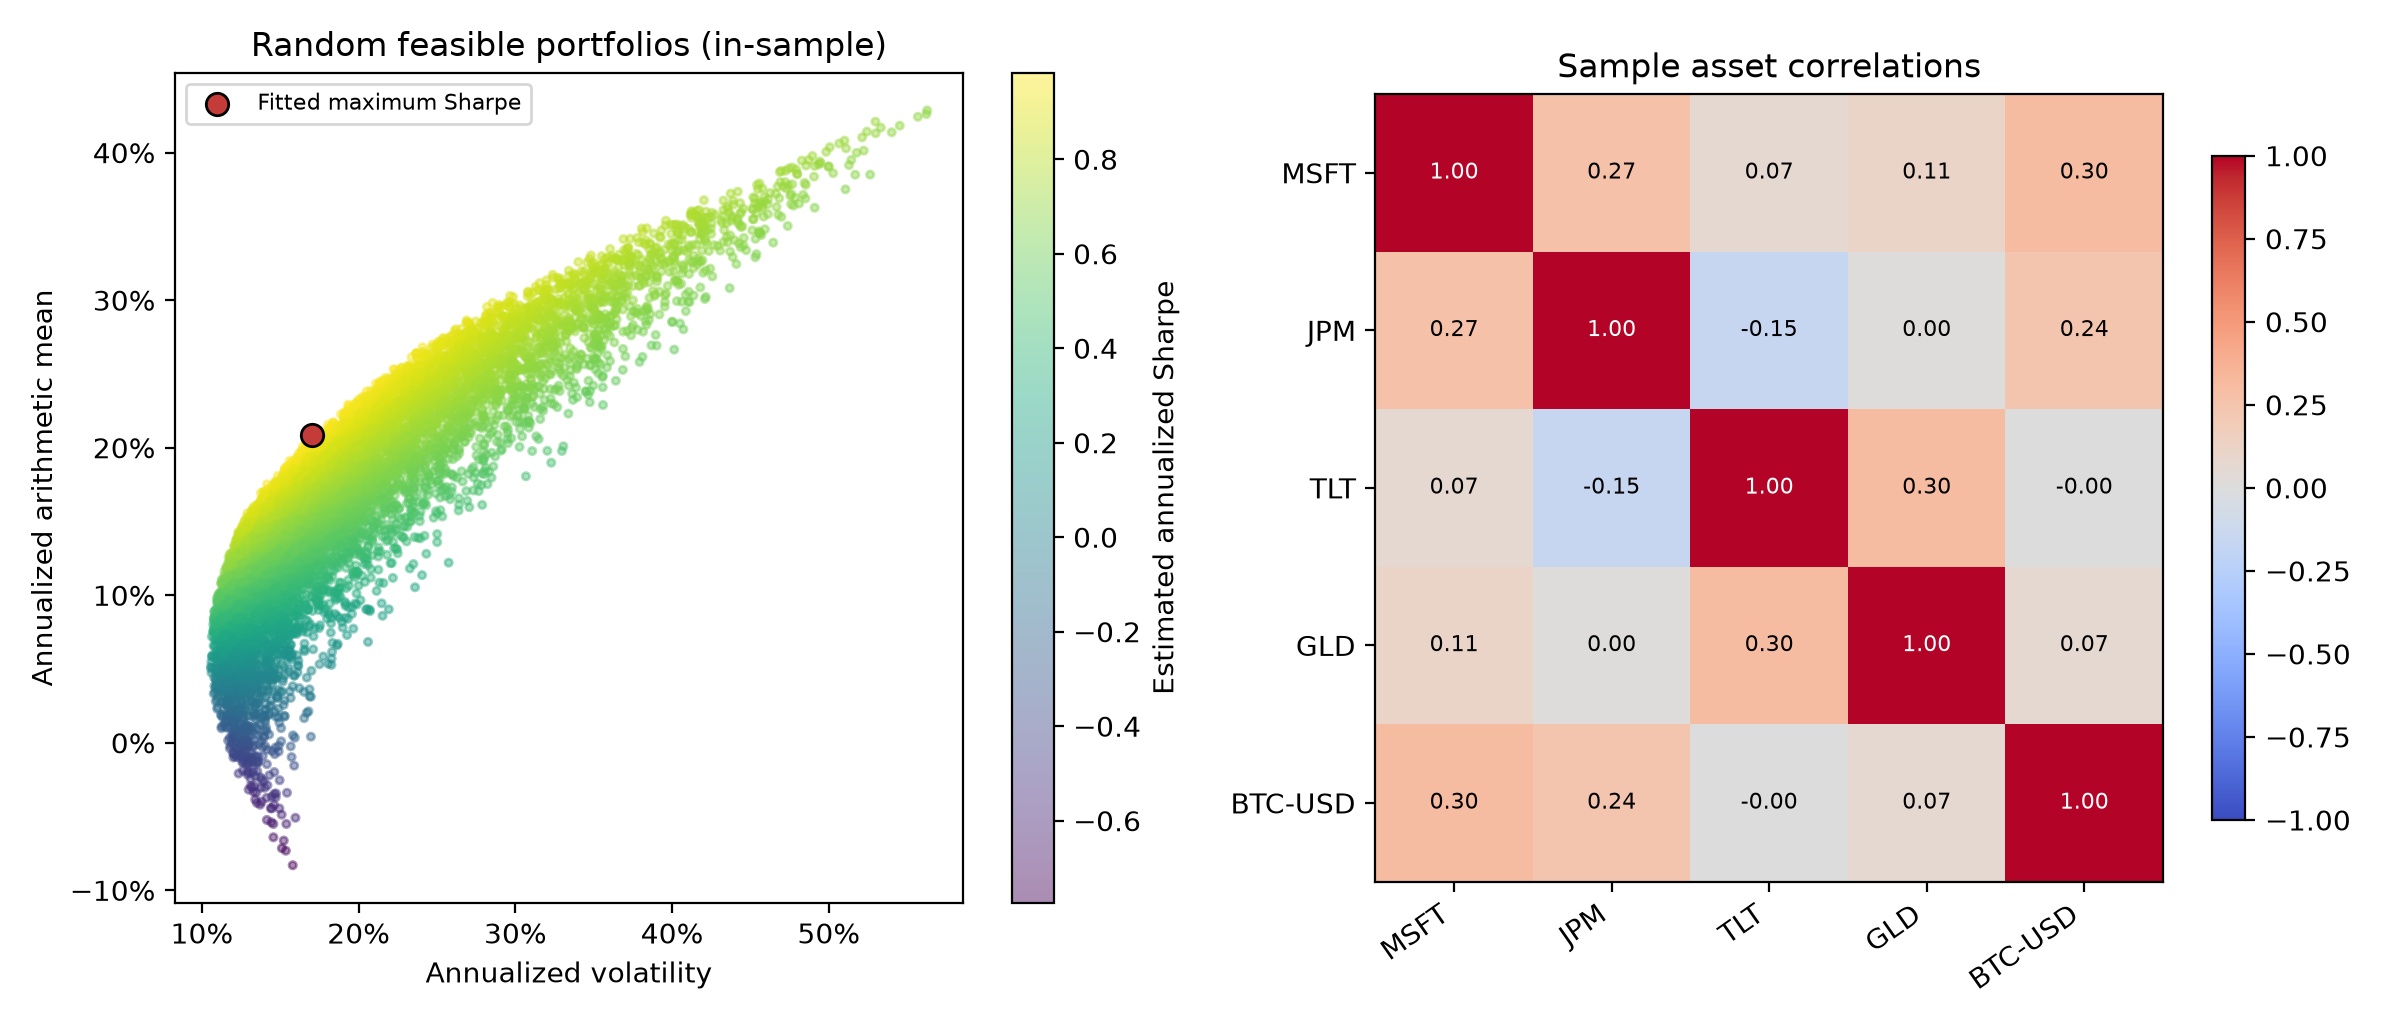

Random seed: 20261005


In [4]:
portfolio_cloud(returns, weights, seed=SEED, draws=10000)
display(Image(filename=str(RESULTS / 'Portfolio_Optimization_Model.png')))
print('Random seed:', SEED)

## 5. In-sample return series

The daily dot product describes restoring these fitted weights each day. We state that assumption explicitly here; the HRP notebook instead holds weights between updates. The historical fifth percentile is an estimated tail threshold, not a confidence interval or a guarantee about future losses. These in-sample measurements are not a matched comparison with the HRP rolling test.

In [5]:
in_sample = fixed_weight_returns(returns, weights)
metrics = performance_metrics(in_sample)
display(pd.Series(metrics, name='in_sample_value').to_frame())
in_sample.rename('daily_rebalanced_in_sample').to_csv(RESULTS / 'mvo-in-sample-returns.csv')

,in_sample_value
observations,1004
first_return_date,2021-01-05T00:00:00
last_return_date,2024-12-31T00:00:00
terminal_wealth,2.163807
total_return,1.163807
annualized_compound_growth_252,0.213776
annualized_arithmetic_mean,0.208298
annualized_volatility,0.170279
sharpe_daily_excess,0.992928
maximum_drawdown,-0.340987


## 6. Simple returns and weighted asset logs

With equal investments, one asset's +10% and the other's -10% produce zero portfolio return. Averaging their log returns does not produce zero. This is why the corrected accounting uses simple returns.

In [6]:
toy_asset_returns = np.array([0.10, -0.10])
toy_weights = np.array([0.5, 0.5])
print('Exact simple portfolio return:', toy_weights @ toy_asset_returns)
print('Exact portfolio log return:', np.log1p(toy_weights @ toy_asset_returns))
print('Weighted asset log returns:', toy_weights @ np.log1p(toy_asset_returns))

Exact simple portfolio return: 0.0
Exact portfolio log return: 0.0
Weighted asset log returns: -0.005025167926750722
